# XOR y redes feedforward

El notebook anterior terminó con un problema: ninguna neurona sola resuelve XOR. Este parte del ejemplo con que Goodfellow, Bengio y Courville abren el capítulo 6 de *Deep Learning*: una red con una capa oculta de dos neuronas que resuelve XOR exactamente. Desde ahí se ven tres ideas del capítulo:

- **La capa oculta transforma el espacio.** No dibuja una frontera más complicada: mueve los puntos a un lugar donde una recta sí alcanza. Es lo que 3Blue1Brown describe, en sus capítulos sobre redes neuronales, como capas que detectan rasgos cada vez más útiles.
- **Que exista una solución no garantiza encontrarla.** Entrenando muchas veces la misma red, una parte se queda atascada.
- **Aproximación universal y profundidad.** Una capa oculta ancha aproxima cualquier función continua, pero varias capas pueden lograr lo mismo con exponencialmente menos neuronas.

**Contenido**

1. Preparación
2. La solución exacta de Goodfellow
3. Qué hace la capa oculta
4. Aprender la solución
5. Por qué algunas redes se atascan
6. Aproximación universal: una capa ancha
7. Profundidad: lo que una capa ancha no logra barato
8. Resumen y ejercicios

## 1. Preparación

In [1]:
import copy
import math

import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
print("Versión de PyTorch:", torch.__version__)

X = torch.tensor([[0.0, 0.0],
                  [0.0, 1.0],
                  [1.0, 0.0],
                  [1.0, 1.0]])
y = torch.tensor([[0.0], [1.0], [1.0], [0.0]])      # XOR

Versión de PyTorch: 2.11.0+cpu


## 2. La solución exacta de Goodfellow

La red tiene una capa oculta de dos neuronas con ReLU y una salida lineal:

$$h = \mathrm{ReLU}(W^\top x + c) \qquad \hat{y} = w^\top h + b$$

El libro (sección 6.1) da estos valores:

$$W = \begin{pmatrix} 1 & 1 \\ 1 & 1 \end{pmatrix} \qquad c = \begin{pmatrix} 0 \\ -1 \end{pmatrix} \qquad w = \begin{pmatrix} 1 \\ -2 \end{pmatrix} \qquad b = 0$$

Los cargamos en una red de PyTorch. `nn.Linear` guarda la matriz como `[salidas, entradas]`, que es $W^\top$; como esta $W$ es simétrica, da lo mismo.

In [2]:
red_exacta = nn.Sequential(nn.Linear(2, 2), nn.ReLU(), nn.Linear(2, 1))

with torch.no_grad():
    red_exacta[0].weight[:] = torch.tensor([[1.0, 1.0], [1.0, 1.0]])
    red_exacta[0].bias[:] = torch.tensor([0.0, -1.0])
    red_exacta[2].weight[:] = torch.tensor([[1.0, -2.0]])
    red_exacta[2].bias[:] = torch.tensor([0.0])

    ocultas = red_exacta[:2](X)          # la salida de la capa oculta, después de ReLU
    salida = red_exacta(X)

print("x        h           ŷ     y")
for xi, hi, si, yi in zip(X, ocultas, salida, y):
    print(f"{xi.tolist()}  {hi.tolist()}  {si.item():.0f}     {yi.item():.0f}")

x        h           ŷ     y
[0.0, 0.0]  [0.0, 0.0]  0     0
[0.0, 1.0]  [1.0, 0.0]  1     1
[1.0, 0.0]  [1.0, 0.0]  1     1
[1.0, 1.0]  [2.0, 1.0]  0     0


La red acierta los cuatro casos sin error. Leída neurona por neurona:

- $h_1 = \mathrm{ReLU}(x_1 + x_2)$ cuenta cuántas entradas están encendidas.
- $h_2 = \mathrm{ReLU}(x_1 + x_2 - 1)$ solo se activa si las dos lo están: es un AND.
- $\hat{y} = h_1 - 2h_2$: cuenta las entradas encendidas y, si son las dos, resta 2. Queda 0, 1, 1, 0.

Cada neurona oculta es un **detector de un rasgo**, y la salida los combina.

## 3. Qué hace la capa oculta

La salida $\hat{y} = h_1 - 2h_2$ es lineal en $h$: es una neurona sola, de las que no pueden con XOR. La diferencia es que no mira $x$, mira $h$. Dibujamos los puntos en los dos espacios:

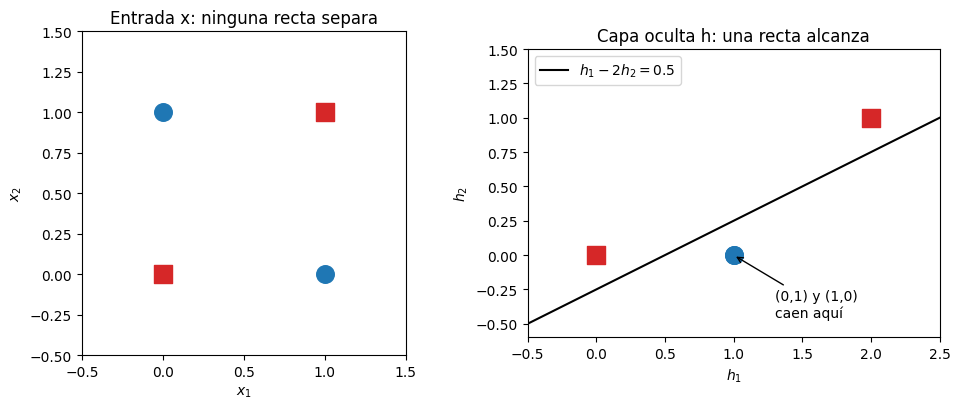

In [3]:
def dibujar_puntos(eje, puntos, etiquetas, titulo, nombres):
    for punto, etiqueta in zip(puntos, etiquetas):
        color, marca = ("tab:blue", "o") if etiqueta == 1 else ("tab:red", "s")
        eje.scatter(punto[0], punto[1], s=160, c=color, marker=marca, zorder=3)
    eje.set_title(titulo)
    eje.set_xlabel(nombres[0])
    eje.set_ylabel(nombres[1])
    eje.set_aspect("equal")


fig, ejes = plt.subplots(1, 2, figsize=(10, 4.2))

dibujar_puntos(ejes[0], X, y.squeeze(), "Entrada x: ninguna recta separa", ("$x_1$", "$x_2$"))
ejes[0].set_xlim(-0.5, 1.5)
ejes[0].set_ylim(-0.5, 1.5)

dibujar_puntos(ejes[1], ocultas, y.squeeze(), "Capa oculta h: una recta alcanza", ("$h_1$", "$h_2$"))
h1 = torch.linspace(-0.5, 2.5, 2)
ejes[1].plot(h1, (h1 - 0.5) / 2, color="black", label="$h_1 - 2h_2 = 0.5$")
ejes[1].annotate("(0,1) y (1,0)\ncaen aquí", xy=(1, 0), xytext=(1.3, -0.45), arrowprops={"arrowstyle": "->"})
ejes[1].set_xlim(-0.5, 2.5)
ejes[1].set_ylim(-0.6, 1.5)
ejes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

La capa oculta **dobla el espacio**: lleva $(0,1)$ y $(1,0)$ al mismo punto $(1, 0)$, y deja $(0,0)$ y $(1,1)$ en lugares distintos. En el espacio nuevo los dos azules son uno solo, y una recta lo separa de los rojos. Una capa oculta no complica la frontera: cambia la representación de los datos hasta que la frontera puede ser simple.

Sin la ReLU esto no funcionaría: la composición de dos funciones lineales es lineal, y la red entera sería una neurona sola (se vio en `01-red-neuronal-simple`, sección 11). El quiebre de la ReLU en 0 es el que dobla el espacio: $h_2$ vale 0 para tres de los puntos y solo se enciende en $(1,1)$.

## 4. Aprender la solución

Goodfellow da los pesos; la pregunta práctica es si el descenso de gradiente los encuentra. Entrenamos la misma arquitectura muchas veces, desde inicializaciones distintas, con MSE y SGD.

Para no repetir el ciclo de entrenamiento 50 veces, entrenamos las 50 redes **a la vez**: apilamos sus pesos en una dimensión extra. `W1` tiene forma `[50, 2, ancho]`, y `X @ W1` calcula las 50 capas ocultas de una vez gracias al broadcasting (sección 8 de `00-fundamentos/02_tensores_a_fondo`). Los pesos parten igual que en `nn.Linear`: uniformes entre $\pm 1/\sqrt{\text{entradas}}$. Como la pérdida total es la suma de las 50 pérdidas, el gradiente de cada red solo depende de su propia pérdida, y es como entrenarlas por separado.

In [4]:
def inicializar(forma, entradas, generador):
    limite = 1 / math.sqrt(entradas)
    return ((torch.rand(forma, generator=generador) * 2 - 1) * limite).requires_grad_()


def entrenar_muchas(ancho, redes=50, pasos=2000, lr=0.1, semilla=0):
    generador = torch.Generator().manual_seed(semilla)
    W1 = inicializar((redes, 2, ancho), 2, generador)
    b1 = inicializar((redes, 1, ancho), 2, generador)
    W2 = inicializar((redes, ancho, 1), ancho, generador)
    b2 = inicializar((redes, 1, 1), ancho, generador)
    optimizador = torch.optim.SGD([W1, b1, W2, b2], lr=lr)

    for _ in range(pasos):
        h = torch.relu(X @ W1 + b1)              # [redes, 4, ancho]
        salida = h @ W2 + b2                     # [redes, 4, 1]
        perdidas = ((salida - y) ** 2).mean(dim=(1, 2))
        optimizador.zero_grad()
        perdidas.sum().backward()
        optimizador.step()

    return perdidas.detach(), [p.detach() for p in (W1, b1, W2, b2)]


resultados = {}
for ancho in [2, 3, 4, 8, 16]:
    perdidas, pesos = entrenar_muchas(ancho)
    resultados[ancho] = (perdidas, pesos)
    resueltas = (perdidas < 1e-3).sum().item()
    print(f"ancho {ancho:2d}: {resueltas:2d} de 50 redes resuelven XOR")

ancho  2:  9 de 50 redes resuelven XOR


ancho  3: 30 de 50 redes resuelven XOR


ancho  4: 33 de 50 redes resuelven XOR


ancho  8: 50 de 50 redes resuelven XOR


ancho 16: 50 de 50 redes resuelven XOR


Con dos neuronas ocultas, la mínima que necesita XOR, solo unas pocas redes llegan a la solución. Con ocho o más, llegan todas. La solución existe en todos los casos (con más neuronas basta apagar las sobrantes), así que la diferencia está en el **entrenamiento**: una red más ancha es más fácil de optimizar.

Las redes que resuelven XOR no llegan a los pesos de Goodfellow, sino a otras soluciones. Hay muchas: por ejemplo, intercambiar las dos neuronas ocultas da otra con la misma pérdida. Miremos la capa oculta de una red de ancho 2 que sí lo resolvió:

In [5]:
perdidas, (W1, b1, W2, b2) = resultados[2]
i = int(torch.nonzero(perdidas < 1e-3)[0])

h = torch.relu(X @ W1[i] + b1[i])
print(f"red {i}: pérdida {perdidas[i]:.1e}")
print("capa oculta h para cada entrada:")
for xi, hi in zip(X, h):
    print(f"  {xi.tolist()} -> [{hi[0]:.2f}, {hi[1]:.2f}]")
print("salida:", (h @ W2[i] + b2[i]).squeeze().round(decimals=3).tolist())

red 4: pérdida 8.5e-13
capa oculta h para cada entrada:
  [0.0, 0.0] -> [0.00, 0.79]
  [0.0, 1.0] -> [0.00, 0.00]
  [1.0, 0.0] -> [1.22, 1.58]
  [1.0, 1.0] -> [0.00, 0.79]
salida: [0.0, 1.0, 1.0, 0.0]


Los números son otros, pero la idea es la misma. Esta red juntó en el mismo punto $h = (0, 0.79)$ a los dos rojos, $(0,0)$ y $(1,1)$, al revés que la solución de Goodfellow, que juntaba a los azules. Con los rojos en un solo punto y cada azul en otro, la salida, que es lineal en $h$, puede separarlos.

## 5. Por qué algunas redes se atascan

Las pérdidas de las redes que no resolvieron XOR no son cualquier número:

In [6]:
for ancho in [2, 3, 4]:
    perdidas = resultados[ancho][0]
    atascadas = perdidas[perdidas >= 1e-3]
    valores, cuantas = torch.unique(atascadas.round(decimals=3), return_counts=True)
    resumen = ", ".join(f"{v:.3f} ({c} redes)" for v, c in zip(valores.tolist(), cuantas.tolist()))
    print(f"ancho {ancho}: {resumen}")

ancho 2: 0.125 (5 redes), 0.167 (12 redes), 0.250 (24 redes)
ancho 3: 0.125 (3 redes), 0.167 (6 redes), 0.250 (11 redes)
ancho 4: 0.125 (6 redes), 0.167 (2 redes), 0.250 (9 redes)


Se repiten tres valores, y cada uno tiene una explicación:

- **0.25**: la red predice 0.5 en los cuatro puntos, la media de las etiquetas. El error es $0.5^2 = 0.25$ en cada uno.
- **0.167**: la red acierta un punto y a los otros tres les asigna la media de sus etiquetas, que es $1/3$. El error promedio es $\big((1/3)^2 + (2/3)^2 + (1/3)^2\big) / 4 = 1/6$.
- **0.125**: acierta dos puntos y a los otros dos les asigna 0.5. El error es $(0.25 + 0.25)/4$.

En todos los casos la red está agrupando puntos que no puede distinguir, y les asigna la misma salida. El motivo es la ReLU: una neurona con $W^\top x + c < 0$ en un punto vale 0 ahí, y su gradiente respecto de sus pesos también es 0. Si una neurona queda apagada en ciertos puntos, el gradiente no tiene cómo encenderla, y la red se queda en una **región plana** de la pérdida. Miremos la capa oculta de una red atascada en 0.25:

In [7]:
perdidas, (W1, b1, W2, b2) = resultados[2]
i = int(torch.nonzero((perdidas - 0.25).abs() < 1e-3)[0])

h = torch.relu(X @ W1[i] + b1[i])
print(f"red {i}: pérdida {perdidas[i]:.3f}")
for xi, hi in zip(X, h):
    print(f"  {xi.tolist()} -> h = [{hi[0]:.2f}, {hi[1]:.2f}]")

red 2: pérdida 0.250
  [0.0, 0.0] -> h = [0.00, 0.23]
  [0.0, 1.0] -> h = [0.00, 0.21]
  [1.0, 0.0] -> h = [0.00, 0.23]
  [1.0, 1.0] -> h = [0.00, 0.21]


La primera neurona vale 0 en los cuatro puntos: está **muerta**. No aporta a la salida y no recibe gradiente, así que nunca va a revivir. La segunda está encendida en los cuatro puntos, y una ReLU encendida en todas partes es simplemente lineal: no dobla nada. Con una neurona de cada tipo, la red completa es una función lineal de $x$, y el mejor ajuste lineal de XOR es la constante 0.5 (XOR no tiene correlación lineal con $x_1$ ni con $x_2$). Ahí se queda: para mejorar, el quiebre de la segunda neurona tendría que entrar en la zona de los datos, y el gradiente no la empuja hacia allá.

Con más neuronas, es poco probable que mueran todas las que hacen falta, y por eso las redes anchas casi siempre llegan. Es un caso concreto de lo que `03-optimalidad` dice en general: la pérdida de una red no es convexa, y desde algunos puntos de partida el descenso de gradiente no llega al mínimo global.

## 6. Aproximación universal: una capa ancha

El **teorema de aproximación universal** (sección 6.4.1 de Goodfellow) dice que una red con una sola capa oculta, con suficientes neuronas, aproxima tan bien como se quiera cualquier función continua en un intervalo acotado.

Con ReLU se puede ver por qué. Cada neurona $\mathrm{ReLU}(x - x_i)$ es una función con un quiebre en $x_i$, y una suma de ellas es una **función lineal por tramos**. Con $n$ neuronas se puede armar la poligonal que une $n + 1$ puntos de cualquier curva:

$$f(x) = f(x_0) + \sum_{i=0}^{n-1} \Delta_i \, \mathrm{ReLU}(x - x_i)$$

donde $\Delta_0$ es la pendiente del primer tramo y cada $\Delta_i$ siguiente es cuánto cambia la pendiente en $x_i$. Construimos esa red a mano para $\sin(x)$ en $[0, 2\pi]$ y la comparamos con `np.interp`, que calcula la misma poligonal:

In [8]:
def red_poligonal(funcion, a, b, n):
    nodos = torch.linspace(a, b, n + 1)
    valores = funcion(nodos)
    pendientes = (valores[1:] - valores[:-1]) / (nodos[1:] - nodos[:-1])
    cambios = torch.cat([pendientes[:1], pendientes[1:] - pendientes[:-1]])

    red = nn.Sequential(nn.Linear(1, n), nn.ReLU(), nn.Linear(n, 1))
    with torch.no_grad():
        red[0].weight[:] = 1.0
        red[0].bias[:] = -nodos[:-1]          # neurona i: ReLU(x - x_i)
        red[2].weight[:] = cambios
        red[2].bias[:] = valores[0]
    return red, nodos, valores


x = torch.linspace(0, 2 * math.pi, 2000).unsqueeze(1)
red, nodos, valores = red_poligonal(torch.sin, 0, 2 * math.pi, n=8)
with torch.no_grad():
    salida = red(x).squeeze(1)

poligonal = torch.from_numpy(np.interp(x.squeeze(1).numpy(), nodos.numpy(), valores.numpy())).float()
print("¿la red es la poligonal?", torch.allclose(salida, poligonal, atol=1e-5))

¿la red es la poligonal? True


Es exactamente la poligonal. El error contra $\sin(x)$ baja a medida que se agregan neuronas:

  4 neuronas: error máximo 0.2105
  8 neuronas: error máximo 0.0704
 16 neuronas: error máximo 0.0188
 32 neuronas: error máximo 0.0048
 64 neuronas: error máximo 0.0012


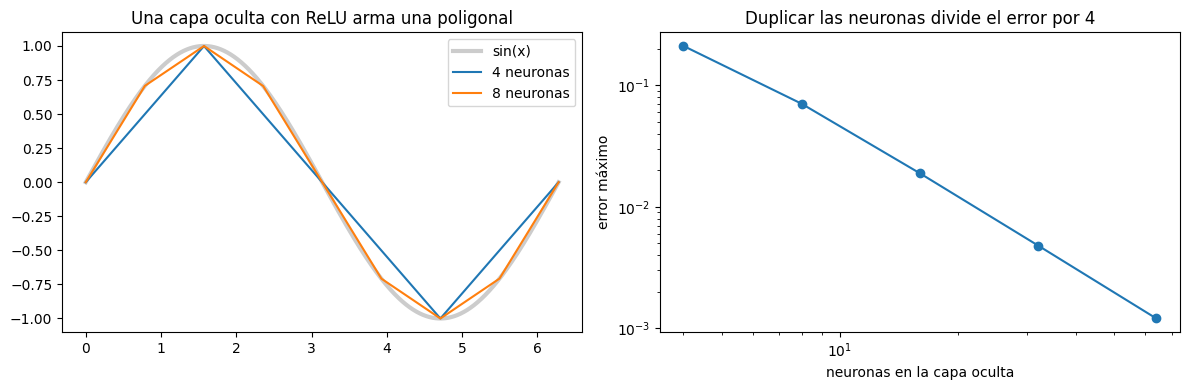

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].plot(x, torch.sin(x), color="gray", linewidth=3, alpha=0.4, label="sin(x)")

anchos = [4, 8, 16, 32, 64]
errores = []
for n in anchos:
    red, _, _ = red_poligonal(torch.sin, 0, 2 * math.pi, n)
    with torch.no_grad():
        salida = red(x)
    errores.append((salida - torch.sin(x)).abs().max().item())
    if n in (4, 8):
        ejes[0].plot(x, salida, label=f"{n} neuronas")
    print(f"{n:3d} neuronas: error máximo {errores[-1]:.4f}")

ejes[0].set_title("Una capa oculta con ReLU arma una poligonal")
ejes[0].legend()
ejes[1].loglog(anchos, errores, "o-")
ejes[1].set_xlabel("neuronas en la capa oculta")
ejes[1].set_ylabel("error máximo")
ejes[1].set_title("Duplicar las neuronas divide el error por 4")
plt.tight_layout()
plt.show()

Cada vez que se duplican las neuronas, el error máximo se divide aproximadamente por 4: va como $1/n^2$, que es el error de interpolar una curva suave con tramos rectos.

El teorema dice que la red **existe**. No dice que el entrenamiento la encuentre, ni cuántas neuronas hacen falta para una función complicada. La sección 4 ya mostró que encontrarla no está garantizado. Aquí probamos si el entrenamiento llega a algo parecido a la poligonal con 16 neuronas:

In [10]:
torch.manual_seed(0)
red_entrenada = nn.Sequential(nn.Linear(1, 16), nn.ReLU(), nn.Linear(16, 1))
optimizador = torch.optim.Adam(red_entrenada.parameters(), lr=0.01)

x_entrenamiento = torch.linspace(0, 2 * math.pi, 200).unsqueeze(1)
for paso in range(3000):
    perdida = ((red_entrenada(x_entrenamiento) - torch.sin(x_entrenamiento)) ** 2).mean()
    optimizador.zero_grad()
    perdida.backward()
    optimizador.step()

with torch.no_grad():
    error_entrenada = (red_entrenada(x) - torch.sin(x)).abs().max().item()
print(f"16 neuronas entrenadas con Adam:  error máximo {error_entrenada:.4f}")
print(f"16 neuronas construidas a mano:   error máximo {errores[anchos.index(16)]:.4f}")

16 neuronas entrenadas con Adam:  error máximo 0.1843
16 neuronas construidas a mano:   error máximo 0.0188


El entrenamiento llega a un error casi 10 veces mayor que la construcción a mano con las mismas 16 neuronas. La diferencia está en dónde quedaron los quiebres. Cada neurona $\mathrm{ReLU}(w x + c)$ se quiebra en $x = -c / w$:

In [11]:
with torch.no_grad():
    pesos = red_entrenada[0].weight.squeeze(1)
    sesgos = red_entrenada[0].bias
    quiebres = -sesgos / pesos
    activas = (torch.relu(x_entrenamiento @ red_entrenada[0].weight.T + sesgos) > 0).any(dim=0)
    dentro = (quiebres > 0) & (quiebres < 2 * math.pi)

print("neuronas encendidas en algún punto del intervalo:", activas.sum().item(), "de 16")
print("quiebres dentro de [0, 2π]:", dentro.sum().item(), "  en x =", [round(q, 2) for q in quiebres[dentro].sort().values.tolist()])

neuronas encendidas en algún punto del intervalo: 8 de 16
quiebres dentro de [0, 2π]: 2   en x = [1.66, 4.62]


La mitad de las neuronas no se enciende en ningún punto del intervalo: están muertas, como en la sección 5. De las otras, casi todas tienen su quiebre fuera del intervalo, así que dentro de él son rectas. La red entrenada terminó usando muy pocos quiebres, mientras que la construida a mano reparte 16 de forma pareja. El ejercicio 6 prueba qué pasa al entrenar más tiempo.

## 7. Profundidad: lo que una capa ancha no logra barato

Si una capa basta, ¿para qué apilar varias? Porque hay funciones que una red profunda representa con pocas neuronas y una de una capa necesita **exponencialmente** más. Goodfellow lo discute en la sección 6.4.1; el ejemplo más limpio es la función "tienda":

$$g(x) = 2\,\mathrm{ReLU}(x) - 4\,\mathrm{ReLU}(x - 0.5) \qquad \text{en } [0, 1]$$

que sube de 0 a 1 en $[0, 0.5]$ y baja de vuelta a 0 en $[0.5, 1]$. Usa dos neuronas. Si se aplica $g$ sobre su propio resultado, cada tramo se vuelve a doblar: $g(g(x))$ tiene 4 tramos, $g(g(g(x)))$ tiene 8, y $k$ composiciones tienen $2^k$ tramos con solo $2k$ neuronas.

 capas   neuronas   tramos   una sola capa necesita al menos
    1          2        2            1
    2          4        4            3
    3          6        8            7
    4          8       16           15


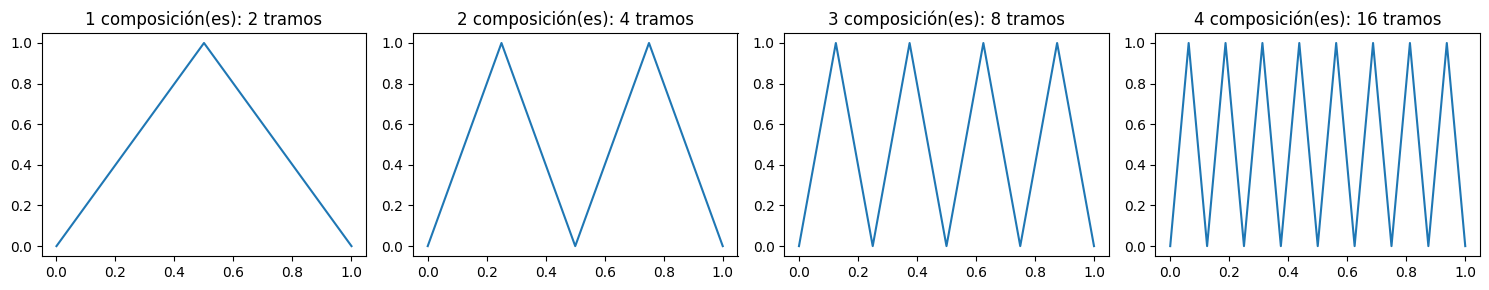

In [12]:
def tienda():
    bloque = nn.Sequential(nn.Linear(1, 2), nn.ReLU(), nn.Linear(2, 1))
    with torch.no_grad():
        bloque[0].weight[:] = torch.tensor([[1.0], [1.0]])
        bloque[0].bias[:] = torch.tensor([0.0, -0.5])
        bloque[2].weight[:] = torch.tensor([[2.0, -4.0]])
        bloque[2].bias[:] = torch.tensor([0.0])
    return bloque


def contar_tramos(red, puntos=2**12 + 1):
    x = torch.linspace(0, 1, puntos, dtype=torch.float64).unsqueeze(1)
    with torch.no_grad():
        valores = copy.deepcopy(red).double()(x).squeeze(1)
    pendientes = (valores[1:] - valores[:-1]) * (puntos - 1)
    quiebres = ((pendientes[1:] - pendientes[:-1]).abs() > 1e-6).sum().item()
    return quiebres + 1


x01 = torch.linspace(0, 1, 2001).unsqueeze(1)
fig, ejes = plt.subplots(1, 4, figsize=(15, 3))
print(" capas   neuronas   tramos   una sola capa necesita al menos")
for k, eje in zip(range(1, 5), ejes):
    red_profunda = nn.Sequential(*[tienda() for _ in range(k)])
    tramos = contar_tramos(red_profunda)
    print(f"{k:5d} {2 * k:10d} {tramos:8d} {tramos - 1:12d}")
    with torch.no_grad():
        eje.plot(x01, red_profunda(x01))
    eje.set_title(f"{k} composición(es): {tramos} tramos")
plt.tight_layout()
plt.show()

La última columna sale de un argumento simple: en una red de una sola capa oculta con entrada de una dimensión, cada neurona aporta a lo más un quiebre (el punto donde su ReLU se enciende), así que $n$ neuronas dan a lo más $n + 1$ tramos. Para $2^k$ tramos hacen falta al menos $2^k - 1$ neuronas. Con 10 composiciones serían 20 neuronas en la red profunda contra al menos 1023 en la de una capa.

Esta es una razón por la que las redes que se usan en la práctica son profundas: cada capa puede reutilizar lo que calcularon las anteriores (aquí, doblar otra vez lo ya doblado), y eso permite representar estructuras con muchas repeticiones a un costo que crece mucho más lento.

## 8. Resumen

- Una capa oculta de dos neuronas con ReLU resuelve XOR exactamente. Cada neurona oculta detecta un rasgo ("cuántas encendidas", "las dos encendidas") y la salida los combina linealmente.
- La capa oculta no complica la frontera: transforma los datos hasta que una frontera lineal alcanza. Sin la activación, la red entera sería lineal.
- Que la solución exista no significa que el entrenamiento la encuentre. Con dos neuronas, la mayoría de las inicializaciones quedan atrapadas en regiones planas creadas por neuronas ReLU apagadas. Con redes más anchas, casi todas llegan.
- Una capa oculta con ReLU arma funciones lineales por tramos, y con suficientes neuronas aproxima cualquier función continua (aproximación universal). Para $\sin(x)$ el error cae como $1/n^2$.
- La profundidad compra eficiencia: componer $k$ veces una función de dos neuronas da $2^k$ tramos, que una sola capa necesitaría $2^k - 1$ neuronas para igualar.

## Ejercicios

1. Cambia la solución de Goodfellow para que calcule XNOR (salida 1 cuando las entradas son iguales) cambiando solo $w$ y $b$.
2. En `entrenar_muchas`, cambia la ReLU por `torch.sigmoid` y repite el experimento con anchos 2 y 4. ¿Cambia la proporción de redes que resuelven XOR? ¿Aparecen los mismos valores de pérdida atascada? Explica la diferencia con lo que dice la sección 5 sobre las neuronas muertas.
3. Repite el experimento de la sección 4 con `pasos=10000`. ¿Alguna red atascada en 0.25 logra salir? ¿Y alguna en 0.125? Usa la sección 5 para explicar el resultado.
4. Usa `red_poligonal` para aproximar $|x|$ en $[-1, 1]$ con 2 neuronas. ¿Por qué el error es 0 (salvo redondeo)?
5. Usa `red_poligonal` para construir una red de **una** capa oculta que calcule exactamente $g(g(x))$ en $[0, 1]$. Pista: le puedes pasar como función la red profunda de dos composiciones, y los nodos tienen que caer en los quiebres. ¿Cuántas neuronas usa? Repite con tres y cuatro composiciones y compara con las $2k$ neuronas de la red profunda.
6. Entrena `red_entrenada` (sección 6) con 30000 pasos en vez de 3000. ¿Cuántos quiebres quedan dentro del intervalo? ¿Cuánto baja el error máximo? ¿Se acerca al de la construcción a mano?